# Hyperparameter Tuning with Optuna
### ML Fundamentals — Supplementary Notebook

---

## What Problem Are We Solving?

Every ML model has **hyperparameters** — settings you choose *before* training that control how the model learns.

For example, in K-Nearest Neighbors:
- How many neighbors `k` should we use? 3? 10? 50?

In Support Vector Machines:
- How strict should the margin be? (`C`)
- What kernel should we use? (`rbf`, `linear`, `poly`?)

Picking bad hyperparameters = bad model. Picking good ones = much better performance.

**The naive approach:** try every combination (GridSearch). Very slow.

**The smart approach:** use an algorithm that *learns* which regions of the search space look promising. That's what **Optuna** does.

---

## Case Study: Predicting Housing Prices

We'll use the classic California Housing dataset and tune a Ridge Regression model, then a more complex pipeline.

In [2]:
# Install Optuna if needed
# !pip install optuna

import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Suppress Optuna's verbose logging for cleaner output
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("✅ All imports successful!")
print(f"Optuna version: {optuna.__version__}")

/Users/samson.afolabi/opt/anaconda3/envs/f2m/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ All imports successful!
Optuna version: 4.8.0


## Load & Explore the Data

In [3]:
# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Shape:", df.shape)
print("\nFeatures:", list(housing.feature_names))
print("\nTarget: MedHouseVal (median house value in $100,000s)")
df.head()

Shape: (20640, 9)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target: MedHouseVal (median house value in $100,000s)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:
# Split into features and target
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

# Train/test split — ALWAYS do this before any tuning!
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples:     {X_test.shape[0]}")
print("\n⚠️  We will NOT touch the test set until the very end.")

Training samples: 16512
Test samples:     4128

⚠️  We will NOT touch the test set until the very end.


## Optuna

### Key Concepts

Optuna works with three building blocks:

| Concept | What it means |
|---|---|
| **Trial** | One experiment with one set of hyperparameters |
| **Study** | A collection of trials — the full optimization run |
| **Objective function** | A Python function you write that takes a trial, returns a score |

You write the objective function. Optuna figures out what to try next.

In [7]:
# ============================================================
# The Objective Function — the heart of every Optuna study
# ============================================================

def objective_ridge(trial):
    """
    This function:
    1. Asks Optuna to suggest a hyperparameter value
    2. Trains a model with that value
    3. Returns a score (Optuna will try to MAXIMIZE this)
    """
    
    # Ask Optuna to suggest an alpha value
    # suggest_float with log=True means it searches on a log scale
    # (good for parameters that span many orders of magnitude)
    alpha = trial.suggest_float('alpha', 1e-4, 1e4, log=True)
    
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=alpha))
    ])
    
    scores = cross_val_score(pipeline, X_train, y_train, 
                             cv=5, scoring='r2')
    return scores.mean()  # Optuna will maximize this


# Create a study and run it
study_ridge = optuna.create_study(direction='maximize')  # we want higher R²
study_ridge.optimize(objective_ridge, n_trials=50)        # run 50 experiments

print("\n🏆 Best trial:")
print(f"   alpha = {study_ridge.best_params['alpha']:.6f}")
print(f"   CV R² = {study_ridge.best_value:.4f}")


🏆 Best trial:
   alpha = 0.000100
   CV R² = 0.6115


## Visualize the Search

One of Optuna's strengths is that it records *every* trial, so we can see exactly what it explored.

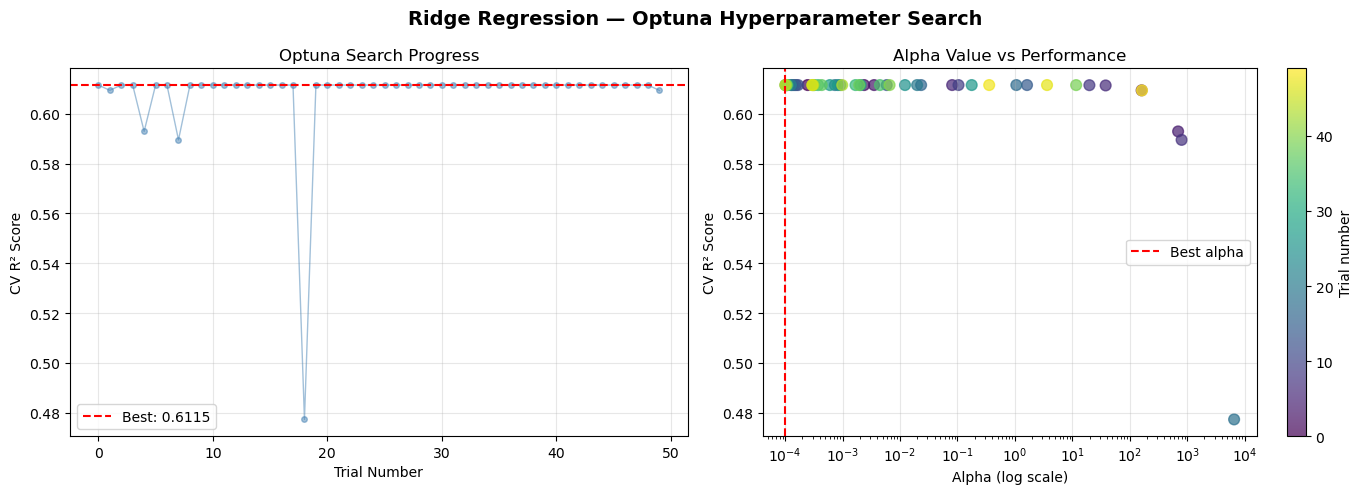

💡 Notice: later trials (yellow) cluster around the best region —
   Optuna is learning where to look!


In [8]:
# Extract trial data
trials_df = study_ridge.trials_dataframe()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Score vs Trial number (shows learning progress)
axes[0].plot(trials_df['number'], trials_df['value'], 
             alpha=0.5, color='steelblue', marker='o', markersize=4, linewidth=1)
axes[0].axhline(y=study_ridge.best_value, color='red', 
                linestyle='--', label=f'Best: {study_ridge.best_value:.4f}')
axes[0].set_xlabel('Trial Number')
axes[0].set_ylabel('CV R² Score')
axes[0].set_title('Optuna Search Progress')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Alpha value vs Score (shows which region was best)
scatter = axes[1].scatter(
    trials_df['params_alpha'], trials_df['value'],
    c=trials_df['number'], cmap='viridis', alpha=0.7, s=60
)
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (log scale)')
axes[1].set_ylabel('CV R² Score')
axes[1].set_title('Alpha Value vs Performance')
axes[1].axvline(x=study_ridge.best_params['alpha'], 
                color='red', linestyle='--', label='Best alpha')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.colorbar(scatter, ax=axes[1], label='Trial number')

plt.suptitle('Ridge Regression — Optuna Hyperparameter Search', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 Notice: later trials (yellow) cluster around the best region —")
print("   Optuna is learning where to look!")

## Final Evaluation on the Test Set

**Important rule:** we only evaluate on the test set **once**, after all tuning is complete.

In [17]:
# Rebuild the best model from the multi-model study
best_params = study_multi.best_params
best_model_name = best_params['model']

print(f"Best model: {best_model_name}")
print(f"Best params: {best_params}")

# Rebuild the best pipeline
if best_model_name == 'ridge':
    final_model = Ridge(alpha=best_params['ridge_alpha'])
elif best_model_name == 'lasso':
    final_model = Lasso(alpha=best_params['lasso_alpha'])
elif best_model_name == 'knn':
    final_model = KNeighborsRegressor(
        n_neighbors=best_params['knn_k'],
        weights=best_params['knn_weights']
    )

final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', final_model)
])

# Train on ALL training data, then evaluate once on test set
final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)

test_r2  = r2_score(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\n🎯 FINAL TEST SET RESULTS")
print(f"   R²   = {test_r2:.4f}")
print(f"   RMSE = {test_rmse:.4f} ($100,000s)  →  ${test_rmse*100_000:,.0f}")

Best model: knn
Best params: {'model': 'knn', 'knn_k': 14, 'knn_weights': 'distance'}

🎯 FINAL TEST SET RESULTS
   R²   = 0.6854
   RMSE = 0.6421 ($100,000s)  →  $64,211


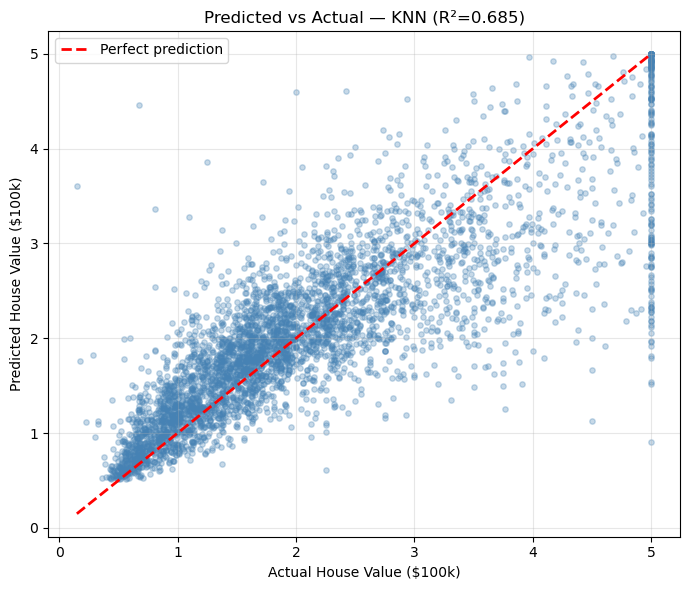

In [18]:
# Predicted vs Actual plot
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(y_test, y_pred, alpha=0.3, s=15, color='steelblue')
ax.plot([y_test.min(), y_test.max()], 
        [y_test.min(), y_test.max()], 
        'r--', linewidth=2, label='Perfect prediction')
ax.set_xlabel('Actual House Value ($100k)')
ax.set_ylabel('Predicted House Value ($100k)')
ax.set_title(f'Predicted vs Actual — {best_model_name.upper()} (R²={test_r2:.3f})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Summary & Key Takeaways

---

### What Optuna Does

| Step | You do | Optuna does |
|------|--------|-------------|
| Define search space | ✅ | |
| Write objective function | ✅ | |
| Decide what to try next | | ✅ (TPE algorithm) |
| Track all results | | ✅ |
| Return best params | | ✅ |

### When to Use What

| Method | Use when |
|--------|----------|
| `GridSearchCV` | Few parameters, small grid, need reproducibility |
| `RandomizedSearchCV` | Medium search space, fast baseline |
| **Optuna** | Many parameters, expensive models, want smart search |